# 05 Anomaly detection on residuals - PVDAQ system 9069

Goal of Phase 5: find inverters that lose power relative to their peers, and measure how small a
loss the detectors can still find. Logic lives in `src/anomalies.py`, `src/synthetic_faults.py`
and `src/outages.py`; this notebook calls it and shows the results.

**Everything labelled SYNTHETIC is generated by `src/synthetic_faults.py` (fixed seed, documented in
the config) and injected into a copy of the real AC data. No real measurement is changed.** The real data
have no fault labels; the only labels for precision / recall are the synthetic ones.

Decisions taken with the author (options first):
- residual = measured / expected AC per inverter, divided by the median of the running inverters at
  the same 5-min step (removes season, weather, soiling, the 2021 and 2023 steps);
- features per inverter-day as deviation from the inverter's own 121-day norm (healthy inverters sit
  at fixed offsets of 0.96 ... 1.05 from their peers);
- three detectors: Isolation Forest on 4 features, Isolation Forest on 2 features, and a plain rule
  (robust z-score of the daily median residual) as the baseline without ML;
- threshold chosen on 2020-2021, reported on 2022-2023 (events that straddle the split are dropped);
- an event counts as detected if >= 3 of its days are flagged.

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, warnings
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import load_config
from src.model import load_inputs, cell_temperature
from src import anomalies as an
from src import outages
from src.synthetic_faults import plan_faults, inject_faults

cfg = load_config("configs/system_9069.yaml")
A = cfg["anomalies"]
inputs, ac = load_inputs(cfg)
t_cell = cell_temperature(inputs, cfg)
print("steps:", len(inputs), "| inverters:", ac.shape[1], "|", inputs.index[0], "->", inputs.index[-1])

steps: 376654 | inverters: 40 | 2020-05-01 00:00:00+00:00 -> 2023-11-29 19:45:00+00:00


## 1. Residual and peer normalisation (real data)
r = measured / expected for every running inverter at every usable step (POA > 200 W/m2, model below 90 % of the
rating, inverter not stopped). rel = r / median(r of the running inverters at that step), needs >= 10 peers.

In [2]:
rel = an.relative_residual(inputs, ac, t_cell, cfg)
print("usable inverter-steps:", int(rel.notna().sum().sum()))
print("rel (peer-normalised):"); print(rel.stack().dropna().describe().round(3))
yearly = rel.groupby(rel.index.tz_convert("America/New_York").year).median().T
print("\nmedian rel per inverter and year (static offsets, first 10 inverters):"); print(yearly.head(10).round(3))

usable inverter-steps: 3525746
rel (peer-normalised):


count    3525746.000
mean           1.010
std            0.233
min            0.016
25%            0.971
50%            1.000
75%            1.030
max            9.589
dtype: float64

median rel per inverter and year (static offsets, first 10 inverters):
time_utc        2020   2021   2022   2023
p_ac_inv01_kw  0.977  0.978  0.989  0.964
p_ac_inv02_kw  0.959  0.959  0.967  0.971
p_ac_inv03_kw  0.988  0.986  0.994  1.000
p_ac_inv04_kw  0.993  0.990  0.997  0.996
p_ac_inv05_kw  1.000  0.995  0.984  0.980
p_ac_inv06_kw  1.009  1.011  1.013  1.028
p_ac_inv07_kw  1.022  1.023  1.022  1.030
p_ac_inv08_kw  0.988  0.998  0.989  0.999
p_ac_inv09_kw  1.003  1.000  1.000  1.014
p_ac_inv10_kw  1.000  0.994  0.991  1.013


In [3]:
feat = an.daily_features(rel, cfg)
print("inverter-days with a daily feature:", len(feat)); print(feat.describe().round(3))
valid_days = feat["rel_median"].unstack().notna()

inverter-days with a daily feature: 40705
       rel_median    rel_p10  frac_below95  rel_spread    n_steps
count   40705.000  40705.000     40705.000   40705.000  40705.000
mean        0.999      0.892         0.175       0.215     86.013
std         0.029      0.108         0.146       0.205     20.436
min         0.099      0.036         0.000       0.006     24.000
25%         0.985      0.844         0.066       0.070     74.000
50%         1.000      0.922         0.149       0.147     90.000
75%         1.016      0.971         0.250       0.298    101.000
max         1.388      1.086         1.000       3.809    126.000


## 2. Noise floor: how small a loss can be seen?
Deviation of the daily median rel from the inverter's own 121-day rolling median. Its robust spread (MAD)
sets the smallest loss that stands out; one string is 1 / 170 of an inverter (170 = 967 kW / (19 x 0.300 kW), derived).

In [4]:
x_real = an.own_norm_features(feat, cfg)
d = x_real["dev_rel_median"]
sigma = 1.4826 * (d - d.median()).abs().median()
n_str = A["synthetic"]["strings_per_inverter"]
print("rows:", len(d), "| std %.4f | robust sigma (MAD) %.4f" % (d.std(), sigma))
print(d.quantile([.001, .01, .05, .5, .95, .99, .999]).round(4).to_dict())
print("3 sigma = %.1f %% of an inverter = %.1f strings" % (300 * sigma, 3 * sigma * n_str))

rows: 40682 | std 0.0166 | robust sigma (MAD) 0.0068
{0.001: -0.135, 0.01: -0.03, 0.05: -0.0162, 0.5: 0.0, 0.95: 0.0162, 0.99: 0.0318, 0.999: 0.0565}
3 sigma = 2.0 % of an inverter = 3.5 strings


## 3. Which inverters stop together, and are the zeros real?
Down-day = below 1 % of the rating on more than half of the known daylight steps. Jaccard = share of
days with a stop that both inverters stop on. Meter check: sum(inverters) / (meter x 1.022) stays near 1.0 when the stops are real
(the meter loses the energy as well) and drops when the zeros are false (lost data channels).

In [5]:
is_down = outages.down_days(ac, inputs["poa_wm2"], cfg)
pairs = outages.pair_overlap(is_down)
pairs["pair"] = pairs.a.str[8:10] + "+" + pairs.b.str[8:10]
print("days down per inverter (min / median / max):", int(is_down.sum().min()), int(is_down.sum().median()), int(is_down.sum().max()))
print(pairs[["pair", "both", "union", "jaccard"]].head(14).round(3).to_string(index=False))

days down per inverter (min / median / max): 9 103 622
 pair  both  union  jaccard
17+18   380    380    1.000
39+40   620    622    0.997
12+18   379    381    0.995
12+17   379    381    0.995
35+36   355    357    0.994
37+38   418    422    0.991
11+12   380    384    0.990
11+18   379    385    0.984
11+17   379    385    0.984
23+24   561    585    0.959
05+06   144    159    0.906
04+05   136    153    0.889
01+04   136    154    0.883
23+40   555    631    0.880


In [6]:
ratio = outages.inverter_meter_ratio(inputs, ac, cfg)
ep = outages.episode_table(is_down, ratio, A["episodes"])
print("healthy days (no inverter down): median ratio %.3f, p5-p95 %.3f-%.3f" % (
    ratio[(is_down.sum(axis=1) == 0)].median(), ratio[(is_down.sum(axis=1) == 0)].quantile(.05), ratio[(is_down.sum(axis=1) == 0)].quantile(.95)))
print(ep.round(3).to_string(index=False))

healthy days (no inverter down): median ratio 1.001, p5-p95 0.980-1.003
     start        end  days                                                                                               stopped  n_stopped               partly  ratio_median  ratio_p5
2020-12-12 2020-12-18     7                         01,02,03,04,05,06,07,08,09,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26         26 31,32,35,36,38,39,40         0.967     0.728
2021-01-02 2021-01-11    10                                                                         29,30,31,32,35,36,37,38,39,40         10                              0.888     0.863
2021-10-01 2021-12-02    63                                                                                           37,38,39,40          4       13,21,22,23,24         0.990     0.938
2022-05-23 2022-10-18   149                                                                               23,24,35,36,37,38,39,40          8                   14         1.006     0.98

## 4. Real events in the residuals (not labels, just a look)
Inverter-days with rel_median < 0.8 on at least 24 valid steps, grouped by inverter.

In [7]:
low = feat[feat.rel_median < 0.8].reset_index()
low["d"] = low.date.dt.strftime("%Y-%m-%d")
print(low.groupby("inverter").agg(days=("d", "size"), first=("d", "min"), last=("d", "max")).to_string())
for inv, a, b in [("p_ac_inv30_kw", "2020-09-01", "2020-11-30"), ("p_ac_inv13_kw", "2021-10-15", "2022-01-15")]:
    s = feat["rel_median"].xs(inv, level="inverter").loc[a:b]
    print(inv, "monthly median rel:", s.groupby(s.index.to_period("M")).median().round(3).to_dict())

               days       first        last
inverter                                   
p_ac_inv09_kw     1  2022-07-29  2022-07-29
p_ac_inv13_kw     7  2021-11-19  2021-12-15
p_ac_inv16_kw     1  2023-09-21  2023-09-21
p_ac_inv30_kw     9  2020-10-24  2020-11-04
p_ac_inv30_kw monthly median rel: {Period('2020-09', 'M'): 0.958, Period('2020-10', 'M'): 0.811, Period('2020-11', 'M'): 0.951}
p_ac_inv13_kw monthly median rel: {Period('2021-10', 'M'): 1.001, Period('2021-11', 'M'): 1.002, Period('2021-12', 'M'): 0.611, Period('2022-01', 'M'): 1.012}


## 5. SYNTHETIC string faults
`plan_faults` draws windows from inverter-days with enough data, away from the real events listed in the config.
A fault of k strings multiplies the AC power of one inverter by (1 - k / 170). **All events below are synthetic.**

In [8]:
events = plan_faults(valid_days, cfg)
print("SYNTHETIC events:", len(events), "| inverters used:", events.inverter.nunique())
print(events.groupby(["duration_days", "strings"]).size().unstack().to_string())
print(events.groupby(events.start.dt.year).size().to_dict())
print(events.head(3).to_string())

SYNTHETIC events: 168 | inverters used: 40
strings        1   2   3   5   10  20  40
duration_days                            
21             12  12  12  12  12  12  12
60             12  12  12  12  12  12  12
{2020: 35, 2021: 71, 2022: 26, 2023: 36}
        inverter      start        end  duration_days  strings  loss_fraction  is_synthetic
0  p_ac_inv17_kw 2020-06-24 2020-07-14             21        1       0.005882          True
1  p_ac_inv11_kw 2020-08-25 2020-09-14             21        1       0.005882          True
2  p_ac_inv09_kw 2023-07-09 2023-07-29             21        1       0.005882          True


In [9]:
ac_synth = inject_faults(ac, events)                       # copy: the real ac is not changed
feat_s = an.daily_features(an.relative_residual(inputs, ac_synth, t_cell, cfg), cfg)
x = an.own_norm_features(feat_s, cfg)
labels = an.day_labels(x.index, events, cfg)
tune, test, ev_tune, ev_test, lab = an.split_by_year(x.index, events, labels, A["forest"]["tune_until"])
print("rows:", len(x), "| labels:", lab.value_counts().to_dict())
print("events: tuning %d, test %d, dropped (straddle the split) %d" % (len(ev_tune), len(ev_test), len(events) - len(ev_tune) - len(ev_test)))
print("SYNTHETIC copy differs from the real AC in %d of %d values (the real `ac` is not modified)" % (int((ac_synth.fillna(-1) != ac.fillna(-1)).sum().sum()), ac.size))

rows: 40682 | labels: {'clean': 33696, 'fault': 6559, 'excluded': 427}
events: tuning 106, test 62, dropped (straddle the split) 0
SYNTHETIC copy differs from the real AC in 984030 of 15066160 values (the real `ac` is not modified)


## 6. Three detectors
Threshold: forest = share of inverter-days flagged (contamination); rule = k robust sigmas below the norm. Chosen on the
tuning years (2020-2021), reported on 2022-2023. Two criteria: **far** = best recall within a budget of 1 % false-alarm days
(headline, used in tables and figures below) and **f1** = best day-level F1. F1 first ran into the edge of the grid twice and picks
operating points with 7-12 % false alarms; its precision also depends on the share of injected faults (16 % of the days), which is not the real fault rate.

In [10]:
fo = A["forest"]
scores = {
    "forest, 4 features": an.forest_scores(x, cfg),
    "forest, 2 features": an.forest_scores(x[fo["features_small"]], cfg),
    "rule (baseline)": an.rule_score(x, sigma=sigma),   # sigma of the REAL data (section 2), not of the injected table
}
by_criterion = {}
for criterion in ("far", "f1"):
    by_criterion[criterion] = {}
    for name, sc in scores.items():
        if name.startswith("forest"):
            thr = {c: sc.quantile(1 - c) for c in fo["contamination_grid"]}
        else:
            thr = {k: float(k) for k in A["rule"]["k_grid"]}
        by_criterion[criterion][name] = an.tune_and_report(
            sc, thr, lab, tune, test, ev_tune, ev_test, cfg, criterion=criterion, far_max=fo["far_max"])
results = by_criterion["far"]            # headline: false-alarm budget (<= %.0f %% of clean days)
print("Tuning years, false-alarm-budget criterion (far_max = %.2f):" % fo["far_max"])
for name, (table, best, s_te, per, flag) in results.items():
    print("==", name, "| chosen:", best)
    print(table[["param", "precision", "recall_days", "recall_events", "false_alarm_days", "far", "f1_days"]].round(4).to_string(index=False))

Tuning years, false-alarm-budget criterion (far_max = 0.01):
== forest, 4 features | chosen: 0.02
 param  precision  recall_days  recall_events  false_alarm_days    far  f1_days
 0.002     0.5152       0.0040         0.0377                16 0.0009   0.0079
 0.005     0.7551       0.0173         0.0472                24 0.0014   0.0338
 0.007     0.7622       0.0255         0.0755                34 0.0020   0.0493
 0.010     0.7511       0.0402         0.1132                57 0.0034   0.0763
 0.015     0.7686       0.0676         0.1509                87 0.0051   0.1242
 0.020     0.7601       0.0926         0.1887               125 0.0074   0.1651
 0.030     0.7233       0.1253         0.2547               205 0.0121   0.2136
 0.050     0.6322       0.1756         0.3491               437 0.0259   0.2748
 0.080     0.5107       0.2235         0.5000               916 0.0542   0.3109
 0.120     0.4178       0.2782         0.6698              1658 0.0981   0.3340
== forest, 2 features 

In [11]:
rows = []
for criterion, res in by_criterion.items():
    for name, (table, best, s_te, per, flag) in res.items():
        rows.append({"criterion": criterion, "detector": name, "chosen": best,
                     "precision": s_te["precision"], "recall_days": s_te["recall_days"],
                     "recall_events": s_te["recall_events"], "false_alarm_days": s_te["false_alarm_days"],
                     "far": s_te["false_alarm_days"] / s_te["clean_days"],
                     "median_first_flag_day": per[per.detected].first_flag_day.median()})
summary = pd.DataFrame(rows).set_index(["criterion", "detector"])
print("TEST years 2022-2023 (%d SYNTHETIC events, %d clean inverter-days):" % (len(ev_test), s_te["clean_days"]))
print(summary.round(3).to_string())

TEST years 2022-2023 (62 SYNTHETIC events, 16800 clean inverter-days):
                              chosen  precision  recall_days  recall_events  false_alarm_days    far  median_first_flag_day
criterion detector                                                                                                         
far       forest, 4 features    0.02      0.571        0.071          0.161               121  0.007                    0.0
          forest, 2 features    0.02      0.589        0.074          0.177               117  0.007                    0.0
          rule (baseline)       5.00      0.910        0.292          0.500                66  0.004                    0.0
f1        forest, 4 features    0.12      0.339        0.292          0.694              1303  0.078                    2.0
          forest, 2 features    0.12      0.410        0.379          0.645              1243  0.074                    0.0
          rule (baseline)       1.00      0.349        0.695 

In [12]:
def k_of_n(per):
    g = per.groupby(["strings", "duration_days"]).detected.agg(["sum", "size"])
    return (g["sum"].astype(int).astype(str) + "/" + g["size"].astype(str)).unstack()
for name, (table, best, s_te, per, flag) in results.items():
    print("== %s: detected / events, TEST years (rows: lost strings, columns: fault duration in days)" % name)
    print(k_of_n(per).to_string())

== forest, 4 features: detected / events, TEST years (rows: lost strings, columns: fault duration in days)
duration_days   21   60
strings                
1              0/6  0/6
2              0/3  0/1
3              0/4  0/1
5              0/5  0/4
10             0/7  0/5
20             1/4  0/5
40             6/6  3/5
== forest, 2 features: detected / events, TEST years (rows: lost strings, columns: fault duration in days)
duration_days   21   60
strings                
1              0/6  0/6
2              0/3  0/1
3              0/4  0/1
5              0/5  0/4
10             0/7  0/5
20             2/4  0/5
40             6/6  3/5
== rule (baseline): detected / events, TEST years (rows: lost strings, columns: fault duration in days)
duration_days   21   60
strings                
1              1/6  0/6
2              0/3  0/1
3              0/4  0/1
5              0/5  1/4
10             7/7  3/5
20             4/4  5/5
40             6/6  4/5


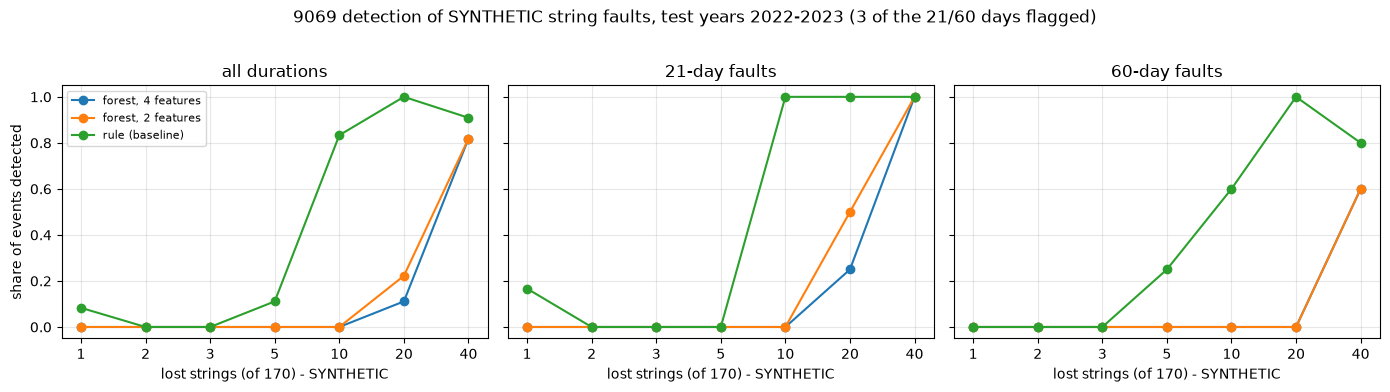

In [13]:
# detection rate by lost strings, all durations pooled, test years; and by duration
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
levels = A["synthetic"]["levels_strings"]
for ax, (title, sel) in zip(axes, [("all durations", None), ("21-day faults", 21), ("60-day faults", 60)]):
    for name, (table, best, s_te, per, flag) in results.items():
        p = per if sel is None else per[per.duration_days == sel]
        rate = p.groupby("strings").detected.mean().reindex(levels)
        ax.plot(range(len(levels)), rate.values, "o-", label=name)
    ax.set_xticks(range(len(levels))); ax.set_xticklabels(levels)
    ax.set(title=title, xlabel="lost strings (of 170) - SYNTHETIC"); ax.grid(alpha=.3)
axes[0].set_ylabel("share of events detected"); axes[0].legend(fontsize=8)
fig.suptitle("9069 detection of SYNTHETIC string faults, test years 2022-2023 (3 of the 21/60 days flagged)", y=1.02)
fig.tight_layout(); fig.savefig("reports/figures/9069_anomaly_detection.png", dpi=130, bbox_inches="tight"); plt.show()

## 7. Real events: do the detectors see them?
inv30 (2020-09-22 ... 11-04, 45 days, two steps) and inv13 (2021-11-19 ... 12-15, intermittent) are real events with unknown cause and were
kept out of the synthetic windows. They are not labels; this only shows what each detector does with them.

In [14]:
idx_inv = x.index.get_level_values("inverter"); idx_d = x.index.get_level_values("date")
real = [("p_ac_inv30_kw", "2020-09-22", "2020-11-04"), ("p_ac_inv13_kw", "2021-11-19", "2021-12-15")]
rows = []
for inv, a, b in real:
    m = (idx_inv == inv) & (idx_d >= a) & (idx_d <= b)
    row = {"event": f"{inv[8:10]} {a}..{b}", "days": int(m.sum())}
    for name, (_, _, _, _, flag) in results.items():
        row[name] = int(flag[m].sum())
    rows.append(row)
print("flagged days inside the real events:"); print(pd.DataFrame(rows).to_string(index=False))
ex = (lab == "excluded").to_numpy()
print("\nflagged share on all excluded rows (real events and plant-wide stops, %d rows):" % ex.sum(),
      {n: round(float(f[ex].mean()), 3) for n, (_, _, _, _, f) in results.items()})

flagged days inside the real events:
                    event  days  forest, 4 features  forest, 2 features  rule (baseline)
30 2020-09-22..2020-11-04    41                   1                   3               38
13 2021-11-19..2021-12-15     7                   7                   7                7

flagged share on all excluded rows (real events and plant-wide stops, 427 rows): {'forest, 4 features': 0.026, 'forest, 2 features': 0.028, 'rule (baseline)': 0.112}


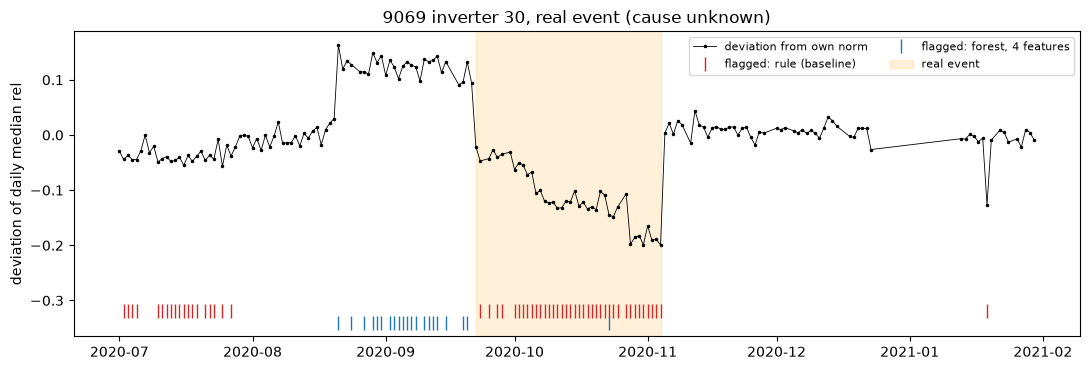

In [15]:
fig, ax = plt.subplots(figsize=(11, 3.8))
m = (idx_inv == "p_ac_inv30_kw") & (idx_d >= "2020-07-01") & (idx_d <= "2021-01-31")
dd = idx_d[m]; ax.plot(dd, x.loc[m, "dev_rel_median"].values, "k.-", ms=3, lw=.6, label="deviation from own norm")
for name, c, off in [("rule (baseline)", "C3", 0.0), ("forest, 4 features", "C0", 0.02)]:
    fl = results[name][4][m].values
    ax.plot(dd[fl], np.full(fl.sum(), -0.32 - off), "|", color=c, ms=10, label="flagged: " + name)
ax.axvspan(pd.Timestamp("2020-09-22"), pd.Timestamp("2020-11-04"), color="orange", alpha=.15, label="real event")
ax.set(ylabel="deviation of daily median rel", title="9069 inverter 30, real event (cause unknown)"); ax.legend(fontsize=8, ncol=2)
fig.tight_layout(); fig.savefig("reports/figures/9069_anomaly_inv30.png", dpi=130); plt.show()

## 8. Conclusions
All detection figures come from **SYNTHETIC** faults injected into the real AC series (168 events, 62 of them in the test years 2022-2023). The real data have no fault labels.

**What the residual shows (real data)**
- Dividing by the peer median removes everything the inverters share. The noise of the daily median around an inverter's own 121-day norm is 0.0068 (robust sigma; plain std 0.0166, heavy tails: the 0.1 % quantile is -0.135). The Gaussian core alone would put 3 sigma at 2.0 % of an inverter = 3.5 strings (170 strings per inverter, derived), but the tails make that limit too optimistic in practice (see below).
- Inverters fail in groups, not pairs: 17+18, 11+12, 11+17 ... (the four 11, 12, 17, 18 share almost all stop days, Jaccard 0.98-1.00), 39+40, 35+36, 37+38, 23+24 (0.96-1.00). Hypothesis, not shown by these files: two inverters of 825 kW per transformer skid, the foursome two skids on one feeder or breaker.
- Stops are mostly real (meter agrees, ratio about 1.00) in 2021-10 ... 2022-12 (inverters 23, 24, 35-40 stopped 2022-05-23 ... 10-18). In 2021-01 and from 2022-12 to 2023-11 the ratio is 0.80-0.91 with 8-14 inverters "stopped": a large share of those zeros are lost data channels, not production loss (the waterfall already credits them).

**Detectors (test years, false-alarm budget of 1 % of clean inverter-days chosen on 2020-2021)**
- The plain rule (daily median below 5 robust sigmas of the real-data noise, i.e. about 3.4 % = 5.8 strings) finds 50 % of the events with 66 false-alarm days (0.4 %), precision 0.91. It finds 10 strings in 7/7 of the 21-day events and 3/5 of the 60-day events, 20 strings in 9/9, 40 strings in 10/11. Of the 30 test events with 1-5 strings only 2 are found (1 string / 21 days: 1 of 6; 5 strings / 60 days: 1 of 4). **Practical detection limit at 1 % false alarms: about 10 strings (about 6 % of an inverter).**
- The Isolation Forest finds 16 % (4 features) and 18 % (2 features) of the events at the same budget, precision 0.57-0.59: it detects 40-string faults (6/6 and 3/5) and sometimes 20 strings (1/4, 2/4 in the 21-day events), nothing below. **The hypothesis that noisy features dilute a weak shift is not supported**: with two features the forest is no better. A possible reason, not tested here: a forest flags points that are isolated in the whole feature space, and a weak but persistent shift of one feature is not isolated.
- Real event inv30 (2020-09-22 ... 11-04, 45 days, two steps): rule flags 38 of 41 days, forests 1 and 3. Real event inv13 (7 days): all three flag 7 of 7. With the 61-day norm window used first, inv30 was invisible (the norm absorbed it); the 121-day window fixed that, at the price that 60-day faults are found less often than 21-day faults (10 strings: 3/5 against 7/7).
- Criterion matters: with max F1 the grid optimum lay at the edge of the grid (forest contamination 0.12, rule k = 1) and the test years show 1 243-2 961 false-alarm days (7-18 %), recall of events 0.65-0.95. Not usable in operation, and its precision depends on the 16 % share of injected fault days, which is not the real fault rate. Both criteria are in the tables above.

**Limits to state wherever these numbers are quoted**
- Synthetic faults are abrupt, constant in size and applied to AC power (not DC before the inverter curve); real faults can creep, flicker or depend on irradiance.
- The test set has 62 events in 14 cells (1-7 per cell): single cells (1/6, 0/4) carry little information, the trend over the number of strings does.
- The own-norm approach absorbs slow real degradation of one inverter and faults longer than about half of the norm window (60 days).
- Precision on synthetic data is not the precision in operation: the real fault rate is unknown and lower than the 16 % of injected days.
- Cause of the real events (inv30, inv13) is unknown; nothing in these files says whether they are strings, combiners or something else.
- A 5-minute localisation level (planned as a second stage) was not built: the daily level already shows that the weak shifts are the problem, not the time resolution. Open.
- The 2023 step of about 3 pp (Phase 4 question) is plant-wide and disappears in the peer normalisation by construction: this phase cannot explain it.
